In [44]:
import Pyro4
import numpy as np
import matplotlib.pyplot as plt
import threading
import time
import os, ntpath
import sys, shutil
from pathlib import Path
from lmfit import Model, create_params
from lmfit.models import LinearModel, LorentzianModel, GaussianModel, VoigtModel, PolynomialModel, ConstantModel

from scipy.fft import fft, ifft, fftfreq

def my_find_nearest(ar,target):
    index = (np.abs(ar - target)).argmin()
    return index


def exponential(t, tau, A):
    return np.exp(-t/tau)*A

def power_law(t, lambd, t0, A):
    return A*t**(-lambd)

def power_law_times_exp(t, tau, t0,lambd, A):
    return A*(t/t0)**(-lambd)*np.exp(-t/tau)

exp_model = Model(exponential, independent_vars=['t'], param_names = ['tau','A'])
powerlaw_model = Model(power_law, independent_vars=['t'], param_names = ['lambd','t0','A'])
powerlaw_exponential_model = Model(power_law_times_exp, independent_vars=['t'], param_names = ['tau', 't0','lambd', 'A'])

## SET UP CLIENT SERVER CONNECTION
Pyro4.config.SERIALIZER = "pickle"
Pyro4.config.SERIALIZERS_ACCEPTED = {"pickle"}
Pyro4.config.SERVERTYPE = "thread"          
Pyro4.config.THREADPOOL_SIZE = 40           
Pyro4.config.THREADPOOL_SIZE_MIN = 4

URI = "PYRO:Analysis_g13@127.0.0.1:9098"
# URI = "PYRO:Analysis_g13@g13-sspd.dhcp-int.phys.ethz.ch:9098"
try:
    stop_logs.set()
except:
    pass

def g2izer(tau, hist, n_new_bins=None, ref_range_s=None,verbose = True):
    if n_new_bins is not None and isinstance(n_new_bins, int):
        if verbose: 
            print(f"Rebinning from {len(tau):d} to {n_new_bins:d}")
        tau_rebin, h_rebin = re_bin(tau*1e9,hist, int(n_new_bins))
        tau_rebin = (tau_rebin).astype(float)*1e-9
    else:
        if verbose: 
            print("Not rebinning")
        tau_rebin, h_rebin = (tau, hist)
    
    binsize = (tau_rebin[1]-tau_rebin[0]) # bin size in ns
    if verbose: 
            print("Bin size ", binsize*1e9, " ns")
    
    # Filter out extreme outliars
    stdv_h_raw = np.std(h_rebin)
    mean_h_raw = np.mean(h_rebin)
    mask_outliars = np.abs(h_rebin - mean_h_raw) < 7*stdv_h_raw
    h_rebin = h_rebin[mask_outliars]
    tau_rebin = tau_rebin[mask_outliars]
    
    if isinstance(ref_range_s, list) and all(isinstance(r, float) for r in ref_range_s):
        if verbose: 
            print(f"Reference range {ref_range_s} s used to correct linear background and show statistics")
            
        bg_range_tau = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]
        histo_bg = h_rebin[bg_range_tau[0]:bg_range_tau[1]]
        tau_bg = tau_rebin[bg_range_tau[0]:bg_range_tau[1]]
        # Evaluate statistics
        h_0 = np.mean(h_rebin[bg_range_tau[0]:bg_range_tau[1]])
        
        # Fit linear background
        bg_fit = LinearModel()
        linear_params = bg_fit.make_params(slope=(h_rebin[-100]-h_rebin[100])/(tau_rebin[-100]-tau_rebin[100])/h_0, intercept=1)
        fitresult = bg_fit.fit(histo_bg/h_0, x = tau_bg)
        # print("Fit slope guess", (h_rebin[-100]-h_rebin[100])/(tau_rebin[-100]-tau_rebin[100]))
        # print("FIt intercept guess", np.mean(h_rebin))
        # print(fitresult.params)
        lin_bg = fitresult.eval(x = tau_rebin)
        h_rebin_detrend = h_rebin - lin_bg*h_0
        stdv_h = np.std(histo_bg - fitresult.eval(x = tau_bg))
        
        return tau_rebin, h_rebin_detrend, stdv_h, h_0
    else:
        return tau_rebin, h_rebin
    
def rebin_plot(tau, hist, n_new_bins=None, ref_range_s=None, lim_x_us= None,lim_y= None, pltname = None, savepath = None, h_offset = 0):
    plt.figure(figsize=(10,2.8))
    if ref_range_s is not None: 
        tau_rebin, h_rebin_detrend, stdv_h, h_0 = g2izer(tau, hist, n_new_bins, ref_range_s)
        bg_range_tau = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]
        plt.plot(tau_rebin*1e6, (h_rebin_detrend)/h_0+h_offset,"-o",markersize=4,label=r"Coincidences per bin")
        plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e6, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0+h_offset,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)

        plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([2*stdv_h, 2*stdv_h])/h_0+h_offset,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
        plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([-2*stdv_h, -2*stdv_h])/h_0+h_offset,linestyle='solid',zorder=0,color='grey')
        plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([0,0])+h_offset,linestyle='solid',zorder=0,color='lightgrey',label="Mean")

        plt.ylabel(r"$g^{(2)}(\tau) - 1$")
    else: 
        tau_rebin, h_rebin = g2izer(tau, hist, n_new_bins, ref_range_s)
        plt.plot(tau_rebin*1e6, h_rebin+h_offset,"-o",markersize=4, label=r"Coincidences per bin (uncorrected)")
        plt.ylabel("Raw coincidences")
    
    if lim_x_us is not None: 
        plt.xlim(-lim_x_us/50, lim_x_us)
        
    if lim_y is not None: 
        plt.ylim(lim_y[0], lim_y[1])
        
    plt.legend()#loc='upper right')
    plt.xlabel(r"Time delay $\tau$ (µs)")
    
    if pltname is not None: 
        plt.title(pltname +"\n"+ f"Time delay bin size = {int((tau_rebin[1]-tau_rebin[0])*1e9):d} ns")
    
    plt.tight_layout()
    if savepath is not None:
        plt.savefig(savepath,dpi = 200)
    
    

def analysis_setup():

    global analysis_cmd # only to pass comannds
    analysis_cmd = Pyro4.Proxy(URI)

    # Separate stop flag for the poller
    global stop_logs
    stop_logs = threading.Event()
    
        
    def log_poller():
        analysis_log = Pyro4.Proxy(URI)  # only for log
        idx = 0
        progress_active = False          # track if last print was a progress line
        while not stop_logs.is_set():
            try:
                idx, lines = analysis_log.get_logs(idx, timeout=2.0)
                for line in lines:
                    if line.startswith("\r"):
                        # progress update: overwrite same line, no newline
                        text = line[1:]  # strip the '\r' tag
                        sys.stdout.write('\r\033[K')
                        sys.stdout.write(text)
                        sys.stdout.flush()
                        progress_active = True
                    else:
                        if progress_active:
                            sys.stdout.write('\n')
                            sys.stdout.flush()
                            progress_active = False
                        print(line, flush=True)
            except Exception as e:
            #     # If poll fails, finish any in-place line so errors don’t append to it
                if progress_active:
                    sys.stdout.write('\n')
                    sys.stdout.flush()
                    progress_active = False
                print(f"[log poller] {e}", flush=True)
                time.sleep(0.5)
            time.sleep(0.2)
            
    t = threading.Thread(target=log_poller, daemon=True)
    t.start()
    print("------------------ LOG ------------------", flush=True)

    analysis_cmd.ping()

def re_bin(tau_bins, h, n_new_bins_approx):
    
    n_original_bins = len(tau_bins)
    len_new_bins = n_original_bins // n_new_bins_approx
    n_new_bins = n_original_bins//len_new_bins           # to make sure we bin cleanly
    
    tau_rebin = np.zeros(n_new_bins,dtype = np.int64)
    h_rebin   = np.zeros(n_new_bins,dtype = np.int64)
    
    for n in range(n_new_bins):
        tau_rebin[n] = np.sum( tau_bins[ n*len_new_bins : (n+1)*len_new_bins ] ) // len_new_bins
        h_rebin  [n] = np.sum( h       [ n*len_new_bins : (n+1)*len_new_bins ] )
    

    return tau_rebin, h_rebin

In [ ]:
analysis_setup()

------------------ LOG ------------------
Analysis server reached.


File Z:\Labs\G13\SSPDs\Olivier & Kilian MoTe2 Correlations\20251120_Esweep_Vmu-2.3_LINSP\E_-0.049Vnm_LINSP_VOA3.3_114nW_window\tests\_chunk0.b: 64688875 records
mode=A1, chunk_ms=1000, tau_min=0.2us, tau_max=100000us, bin=40000.0ps
ticks: min=50000, max=25000000000, bin=10000, nbins=2499995
Found 12814051 overflow markers.
Restricting to first 50 chunks.
Built 50 chunks in 1.6s.
Tasks100.0 % done, elapsed 9.9s  ETA 0.0ss
Correlation done in 10.3s; ch0=89486, ch1=98367
Correlation done.
[classical] File Z:\Labs\G13\SSPDs\Olivier & Kilian MoTe2 Correlations\20251120_Esweep_Vmu-2.3_LINSP\E_-0.049Vnm_LINSP_VOA3.3_114nW_window\tests\_chunk0.b (64688875 records)
[classical] dt=5 ms (dt_ticks=1250000000), chunk=23.333333333333332 min (chunk_ticks=350000000000000) -> 280000 bins/chunk including channels (none = all): 1.
 [classical autocorrelation] processed 100.0% (64688875/64688875) records
[classical] done in 4.0 s. Wrote 8 chunks to: Z:\Labs\G13\SSPDs\Olivier & Kilian MoTe2 Correlations\20

In [ ]:

base = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251120_Esweep_Vmu-2.3_LINSP'
Es1 = np.arange(0,-0.04,-0.005)
# Es2 = np.arange(-0.049,-0.063,-0.001)
Es2 = [-0.064]
filepaths = [f"E_{E:.3f}Vnm"+r"_LINSP_VOA3.3_114nW_window\tests\_"+f"chunk0.b" for E in Es2]

for path in filepaths:
    filepath = ntpath.join(base, path)
    tau, hist, n_records = analysis_cmd.correlate_b_file_highperf(filepath,
                                                   chunk_ms=500,         # chunk size in ms, this can blow up quickly... should scale up carefully
                                                   tau_min_us= 0.2,     # tau max in microseconds
                                                   tau_max_us= 1000,     # tau max in microseconds
                                                   tau_bin_ps= 40e3,    # bin width in ps 
                                                   n_workers= max(1, 8-1), 
                                                   mode = "all",
                                                   only_n_events = False,
                                               show_progress=True)
    print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
    print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 

In [ ]:

# Read existing file

base = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251120_Esweep_Vmu-2.3_LINSP'
Es = np.arange(0,-0.04,-0.005)
Es = np.arange(-0.040,-0.063,-0.001)
Es = [-0.064]


filepaths = [f"E_{E:.3f}Vnm"+r"_LINSP_VOA3.3_114nW_window\tests\_chunk0.b" for E in Es]

for file in filepaths:
    filepath = ntpath.join(base,file)
    # Get the data
    hist, tau, params = analysis_cmd.read_existing(ntpath.dirname(filepath),  mode = "all", name = ntpath.basename(filepath)[:-2])
    
    n_new_bins = int(len(tau)/70)
    pltname = file.strip("\\").replace("\\", "_")[:-2]
    savename = ntpath.join(ntpath.dirname(filepath)+f"{pltname}.png")
    ref_range_s = [500e-6,1000e-6]

    # Plot it
    rebin_plot(tau, hist, n_new_bins = n_new_bins, ref_range_s = ref_range_s, lim_x_us = 1000,  lim_y = [-0.005,0.028],pltname = pltname, savepath = savename)



# Classical autocorrelation

In [ ]:
analysis_setup()

In [ ]:
# filepath_classical = r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251118_highpower\E_-0.062Vnm_LINSP\tests\_chunk2.b"

E = -0.061

base = r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251120_Esweep_Vmu-2.3_LINSP"
base = r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251124_Bsweep_Vmu-2.3_E-0.05_LINSP"

folder = f"E_{E:.3f}Vnm_"+r"LINSP_VOA3.3_114nW_window\tests\_chunk0.b"
folder = r"B_-0.005_-0.05Vnm_LINSP_VOA3.3_114nW_window\tests\_chunk0.b"

base = r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251125_powersweep_Vmu-2.3_E-0.05_B-0.002_LINSP'
folder = r"VOA_3.3_LINSP\tests"

filepath_classical = ntpath.join(base, folder)

tau_bin_ms = 0.25  
BASE_RES = 4e-12

out_dir, files = analysis_cmd.correlate_b_file_classical(
    filepath= filepath_classical,
    tau_bin_ms=tau_bin_ms,          
    chunk_minutes=60,         
    block_records=10_000_000, # tune to RAM
    include_channels=None, # none = all channels
    show_progress=True
)


In [ ]:

folder = f"E_{E:.3f}Vnm_"+r"LINSP_VOA3.3_114nW_window\tests\_chunk0_classical_bins"
folder = r"B_-0.005_-0.05Vnm_LINSP_VOA3.3_114nW_window\tests\_chunk0_classical_bins"

out = analysis_cmd.read_existing_classical(ntpath.join(base, folder), tau_bin_ms=tau_bin_ms, chunk_range = (0,1))
counts_list, dt_s_list, chunk_minutes_list, chunk_index_list,t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx = out

print("Indices of chunks loaded: ",np.array(chunk_index_list))
print("Chunk durations (min):",chunk_minutes_list)
print("Absolute time (s): ", np.round(np.array(t0_abs_ticks_list)*BASE_RES))
print("Bin size (ms): ", np.array(dt_s_list)*1e3)
nbins = np.shape(np.array(counts_list))[1]
print("Bins in each chunk (million): ", nbins/1e6)


In [ ]:



n_new_bins = nbins/100
print("New bins in each chunk (million): ", n_new_bins/1e6)

# DO it for one, then get shape for all
t = np.arange(0,len(counts_list[0]))*dt_s_list[0]
t_rebin,h_rebin = re_bin(t*1e3,np.array(counts_list[0]), int(n_new_bins))
signal = (h_rebin - np.mean(h_rebin))/np.mean(h_rebin)
histo_bins = np.linspace(-1,1,100)
hist_all, histo_bins = np.histogram(signal, bins = histo_bins)

# biased_norm = n_new_bins - np.concatenate((np.flip(np.arange(len(signal))), np.arange(1,len(signal))))
ac = np.correlate(signal, signal, mode='full')#/ biased_norm#/np.mean(h_rebin)
# ac /= ac[my_find_nearest(l,0)]
l = np.arange(-len(signal)+1, len(signal)) * (t_rebin[1] - t_rebin[0]) # this in ms

ac_all = np.zeros((len(ac), len(chunk_index_list)))
ac_all[:,0] = ac 
bin_size = (t_rebin[1]-t_rebin[0])/1e3
print("Bin size: ", bin_size, " s")





for chunk_id in range(1,len(chunk_index_list)):
    t = np.arange(0,len(counts_list[chunk_id]))*dt_s_list[chunk_id]
    t_rebin,h_rebin = re_bin(t*1e3,np.array(counts_list[chunk_id]), int(n_new_bins))
    signal = (h_rebin - np.mean(h_rebin))/np.mean(h_rebin)
    biased_norm = n_new_bins - np.concatenate((np.flip(np.arange(len(signal))), np.arange(1,len(signal))))
    ac = np.correlate(signal, signal, mode='full')#/ biased_norm#/np.mean(h_rebin)
    # ac /= ac[my_find_nearest(l,0)]
    l = np.arange(-len(signal)+1, len(signal)) * (t_rebin[1] - t_rebin[0]) # this in ms
    ac_all[:,chunk_id] = ac    
    hist_time_loc, bins = np.histogram(signal,bins = histo_bins)
    hist_all+= hist_time_loc
    fig, ax = plt.subplots(1,2,figsize=(8,4))
    plt.sca(ax[0])
    plt.scatter(t_rebin/1e3+60*chunk_id, h_rebin ,s = 0.3)
    plt.sca(ax[1])    

    plt.scatter(l,ac,s = 1)
    plt.xlim(0,1000)
    plt.xlabel("Measurement time (s)")
    plt.ylabel(f"Count rate per {int(bin_size*1000):d} ms bin")
    plt.show()

    
    


In [ ]:


fig, ax = plt.subplots(1,2,figsize = (7,4))


autocorr_range = [bin_size*1e3*2, 10e3]
plt.sca(ax[1])
ac = np.sum(ac_all,axis = 1)
l_range = l[(l > autocorr_range[0]) & (l < autocorr_range[1])]
ac_range = ac[(l > autocorr_range[0]) & (l < autocorr_range[1])]
# plt.scatter(l_range, ac_range-ac_range[-1], s= 4) # now plotting against seconds
# plt.yscale('log')
plt.plot(l_range/1e3,ac_range , "-o", markersize = 4) # now plotting against s
plt.ylabel("Autocorrelation signal")

plt.xlabel("Time delay (s)")


ax[0].plot(hist_all, histo_bins[:-1],"-o",markersize = 4)
ax[0].set_ylabel("Avg count rate (Hz)")
ax[0].set_xlabel("Occurence")
ax[0].set_ylim(-0.8,0.8)


fig.tight_layout()


plt.suptitle(folder)
plt.tight_layout()
plt.savefig(ntpath.join(base,folder[:-1]+f"E_{E:.3f}.png"), dpi = 250)
plt.show()


In [ ]:
# filepath_classical = r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251118_highpower\E_-0.062Vnm_LINSP\tests\_chunk2.b"


Es = np.concatenate((np.arange(0,-0.04,-0.005), np.arange(-0.040,-0.062,-0.001)))

ac_ranges = []
l_ranges = []
histo_all = []

for iE in range(len(Es)):
    E = Es[iE]
    base = r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251120_Esweep_Vmu-2.3_LINSP"
    folder = f"E_{E:.3f}Vnm_"+r"LINSP_VOA3.3_114nW_window\tests\_chunk0.b"
    filepath_classical = ntpath.join(base, folder)

    tau_bin_ms = 0.25  
    BASE_RES = 4e-12

    out_dir, files = analysis_cmd.correlate_b_file_classical(
        filepath= filepath_classical,
        tau_bin_ms=tau_bin_ms,          
        chunk_minutes=10/60,         
        block_records=10_000_000, # tune to RAM
        include_channels=None, # none = all channels
        show_progress=True
    )



    folder = f"E_{E:.3f}Vnm_"+r"LINSP_VOA3.3_114nW_window\tests\_chunk0_classical_bins"

    out = analysis_cmd.read_existing_classical(ntpath.join(base, folder), tau_bin_ms=tau_bin_ms, chunk_range = (0,83*6))
    counts_list, dt_s_list, chunk_minutes_list, chunk_index_list,t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx = out

    # print("Indices of chunks loaded: ",np.array(chunk_index_list))
    # print("Chunk durations (min):",chunk_minutes_list)
    # print("Absolute time (s): ", np.round(np.array(t0_abs_ticks_list)*BASE_RES))
    # print("Bin size (ms): ", np.array(dt_s_list)*1e3)
    nbins = np.shape(np.array(counts_list))[1]
    print("Bins in each chunk (million): ", nbins/1e6)





    n_new_bins = nbins/10
    print("New bins in each chunk (million): ", n_new_bins/1e6)

    # DO it for one, then get shape for all
    t = np.arange(0,len(counts_list[0]))*dt_s_list[0]
    t_rebin,h_rebin = re_bin(t*1e3,np.array(counts_list[0]), int(n_new_bins))
    signal = (h_rebin - np.mean(h_rebin))/np.mean(h_rebin)
    histo_bins = np.linspace(-1,1,100)
    hist_all, histo_bins = np.histogram(signal, bins = histo_bins)

    # biased_norm = n_new_bins - np.concatenate((np.flip(np.arange(len(signal))), np.arange(1,len(signal))))
    ac = np.correlate(signal, signal, mode='full')#/ biased_norm#/np.mean(h_rebin)
    # ac /= ac[my_find_nearest(l,0)]
    l = np.arange(-len(signal)+1, len(signal)) * (t_rebin[1] - t_rebin[0]) # this in ms

    ac_all = np.zeros((len(ac), len(chunk_index_list)))
    ac_all[:,0] = ac 
    bin_size = (t_rebin[1]-t_rebin[0])/1e3
    print("Bin size: ", bin_size, " s")





    for chunk_id in range(1,len(chunk_index_list)):
        t = np.arange(0,len(counts_list[chunk_id]))*dt_s_list[chunk_id]
        t_rebin,h_rebin = re_bin(t*1e3,np.array(counts_list[chunk_id]), int(n_new_bins))
        signal = (h_rebin - np.mean(h_rebin))/np.mean(h_rebin)
        biased_norm = n_new_bins - np.concatenate((np.flip(np.arange(len(signal))), np.arange(1,len(signal))))
        ac = np.correlate(signal, signal, mode='full')#/ biased_norm#/np.mean(h_rebin)
        # ac /= ac[my_find_nearest(l,0)]
        l = np.arange(-len(signal)+1, len(signal)) * (t_rebin[1] - t_rebin[0]) # this in ms
        ac_all[:,chunk_id] = ac    
        hist_time_loc, bins = np.histogram(signal,bins = histo_bins)
        hist_all+= hist_time_loc
        # fig, ax = plt.subplots(1,2,figsize=(8,4))
        # plt.sca(ax[0])
        # plt.scatter(t_rebin/1e3+60*chunk_id, h_rebin ,s = 0.3)
        # plt.sca(ax[1])    

        # plt.scatter(l,ac,s = 1)
        # plt.xlim(0,1000)
        # plt.xlabel("Measurement time (s)")
        # plt.ylabel(f"Count rate per {int(bin_size*1000):d} ms bin")
        # plt.show()



    fig, ax = plt.subplots(1,2,figsize = (7,4))


    autocorr_range = [bin_size*1e3*2, 10e3]
    plt.sca(ax[1])
    ac = np.sum(ac_all,axis = 1)
    l_range = l[(l > autocorr_range[0]) & (l < autocorr_range[1])]
    ac_range = ac[(l > autocorr_range[0]) & (l < autocorr_range[1])]
    # plt.scatter(l_range, ac_range-ac_range[-1], s= 4) # now plotting against seconds
    # plt.yscale('log')
    plt.plot(l_range/1e3,ac_range , "-o", markersize = 4) # now plotting against s
    plt.ylabel("Autocorrelation signal")

    plt.xlabel("Time delay (s)")
    ac_ranges.append(ac_range)
    l_ranges.append(l)
    histo_all.append(hist_all)

    ax[0].plot(hist_all, histo_bins[:-1],"-o",markersize = 4)
    ax[0].set_ylabel("Fluctuation (normalized) (Hz)")
    ax[0].set_xlabel("Occurence")
    ax[0].set_ylim(-0.8,0.8)


    fig.tight_layout()


    plt.suptitle(folder)
    plt.tight_layout()
    # plt.savefig(ntpath.join(base,folder[:-1]+f"E_{E:.3f}.png"), dpi = 250)
    plt.savefig(ntpath.join(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251120_Esweep_Vmu-2.3_LINSP\Count rate histograms",f"E_{E:.3f}.png"), dpi = 250)
    




    


In [ ]:
fig, ax = plt.subplots(1,2,figsize = (7,4))


autocorr_range = [bin_size*1e3*2, 10e3]

widths =np.zeros(len(Es))
from lmfit import Model

def gaussian(x, amp, cen, wid):
    wid = float(wid)
    wid = max(wid, 1e-12)
    return amp * np.exp(-(x-cen)**2 / wid)

gmodel = Model(gaussian)
params = gmodel.make_params(cen=0., amp=10e3, wid=0.2)

for iE in range(len(Es)):
    plt.sca(ax[1])
    ac_range = ac_ranges[iE]
    hist_all = np.array(histo_all[iE])
    l_range = l_ranges[iE]

    l_range = l[(l > autocorr_range[0]) & (l < autocorr_range[1])]
    # ac_range = ac[(l > autocorr_range[0]) & (l < autocorr_range[1])]
    # plt.scatter(l_range, ac_range-ac_range[-1], s= 4) # now plotting against seconds
    # plt.yscale('log')

    plt.plot(l_range/1e3,ac_range/ac_range[0] , "-o", markersize = 1) # now plotting against s
    plt.ylabel("Autocorrelation signal")
    plt.xlim(0,1)
    plt.xlabel("Time delay (s)")
    
    ax[0].plot(hist_all, histo_bins[:-1],"-o",markersize = 4)

    result = gmodel.fit(hist_all, params, x=histo_bins[:-1],nan_policy = 'omit')
    widths[iE] = result.params['wid'].value
    ax[0].set_ylabel("Fluctuation (normalized) (Hz)")
    ax[0].set_xlabel("Occurence")
    ax[0].set_ylim(-0.8,0.8)


fig.tight_layout()


# plt.savefig(ntpath.join(base,folder[:-1]+f"E_{E:.3f}.png"), dpi = 250)
# plt.savefig(ntpath.join(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251120_Esweep_Vmu-2.3_LINSP\Count rate histograms",f"E_{E:.3f}.png"), dpi = 250)
savepath = ntpath.join(r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251120_Esweep_Vmu-2.3_LINSP\Count rate histograms",f"Esweep_")
np.save(savepath+"norm_histograms_0.0025s_10s.npy",np.array(histo_all))
np.save(savepath+"lags_0.0025s_10s.npy",np.array(l_ranges))
np.save(savepath+"acs_0.0025s_10s.npy",np.array(ac_ranges))
plt.figure(figsize = (4,3))
plt.scatter(Es*1e3, widths)
plt.xlabel("Electric field (mV/nm)")
plt.ylabel("Width of Gaussian PDF")


In [ ]:
np.mean(h_rebin)


In [ ]:
#### LOOP OVER ELECTRIC FIELDS

Es1 = np.arange(0,-0.04,-0.005)
Es2 = np.arange(-0.040,-0.062,-0.001)

Es = np.concatenate((Es1, Es2))
chunks = np.zeros_like(Es,dtype=int)
chunks[my_find_nearest(Es, -0.048)] = 1
chunks[my_find_nearest(Es, -0.045):my_find_nearest(Es, -0.047)+1] = 2
chunks[my_find_nearest(Es, -0.041)] = 0


all_histos = []
all_bins = []

for iE in range(len(Es)):
    base = r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251120_Esweep_Vmu-2.3_LINSP"
    folder = f"E_{Es[iE]:.3f}Vnm_"+r"LINSP_VOA3.3_114nW_window\tests"
    c = chunks[iE]
    tau_bin_ms = 20
    BASE_RES = 4e-12
    # if np.abs(Es[iE])<0.049:
    #     chunk_mins = 1.5*50
    # else: 
    #     chunk_mins = 3*50
    chunk_mins = 1.5*50
    # out_dir, files = analysis_cmd.correlate_b_file_classical(
    #     filepath= os.path.join(os.path.join(base, folder),  f"_chunk{c}.b"),
    #     tau_bin_ms=tau_bin_ms,          
    #     chunk_minutes=chunk_mins,         
    #     block_records=10_000_000, # tune to RAM
    #     include_channels=None, # none = all channels
    #     show_progress=True
    # )


    out = analysis_cmd.read_existing_classical(os.path.join(os.path.join(base, folder),f"_chunk{c}_classical_bins"), tau_bin_ms=tau_bin_ms, chunk_range = (0,0))
    counts_list, dt_s_list, chunk_minutes_list, chunk_index_list,t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx = out

    print("Indices of chunks loaded: ",np.array(chunk_index_list))
    print("Chunk durations (min):",chunk_minutes_list)
    print("Absolute time (s): ", np.round(np.array(t0_abs_ticks_list)*BASE_RES))
    print("Bin size (s): ", np.array(dt_s_list)*1e3, " s")
    nbins = np.shape(np.array(counts_list))[1]
    print("Bins in each chunk (million): ", nbins/1e6)

    n_new_bins = nbins
    print("New bins in each chunk (million): ", n_new_bins/1e6)

    # DO it for one, then get shape for all
    t = np.arange(0,len(counts_list[0]))*dt_s_list[0]
    t_rebin,h_rebin = re_bin(t*1e3,np.array(counts_list[0]), int(n_new_bins))
    bin_size = (t_rebin[1]-t_rebin[0])/1e3
    print("Bin size: ", bin_size, " s")

    fig, ax = plt.subplots(1,2,figsize = (8,3))
    ax[0].scatter(t_rebin/1e3, h_rebin/bin_size ,s = 1)

    ax[0].set_ylabel("Avg count rate (Hz)")
    ax[0].set_xlabel("Time (s)")
    pltname = folder.strip("\\").replace("\\", "")
    hist_time, bins = np.histogram(h_rebin,bins = 50)
    ax[1].plot(hist_time/bin_size, bins[:-1],"-o",markersize = 4)
    ax[1].set_ylabel("Avg count rate (Hz)")
    ax[1].set_xlabel("Occurence")
    fig.suptitle(folder)
    fig.tight_layout()
    # plt.savefig(r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251120_Esweep_Vmu-2.3_LINSP\Count rate histograms\countrates_'+pltname+'.png',dpi = 200)    
    plt.show()

    all_histos.append(hist_time/chunk_mins)
    all_bins.append(bins[:-1])

all_histos  = np.array(all_histos)
all_bins = np.array(all_bins)

In [ ]:
fig, ax = plt.subplots(5,1,figsize = (4,10))
j=0
plt.sca(ax[0])
for iE in range(len(Es)):
    plt.sca(ax[iE//6])
    plt.plot(all_bins[iE,:],all_histos[iE,:],label=f"E = {int(Es[iE]*1e3):d}V/nm")
    
    if (iE+1)%6==0 or iE == len(Es)-1:
        plt.legend()
        plt.xlim(0,250)
        plt.ylim(0,320)
        plt.ylabel("Occurence")
        plt.xlabel("Counts (Hz)")
        j=+1
fig.tight_layout()      
plt.savefig(r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251120_Esweep_Vmu-2.3_LINSP\Count rate histograms\countrate_histograms_20ms_bins.png', dpi = 250)


# Evaluating frequency decomposition

In [ ]:

E = -0.047

base = r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251120_Esweep_Vmu-2.3_LINSP"
base = r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251124_Bsweep_Vmu-2.3_E-0.05_LINSP"

folder = f"E_{E:.3f}Vnm_"+r"LINSP_VOA3.3_114nW_window\tests\_chunk0.b"
folder = r"B_-0.008_-0.05Vnm_LINSP_VOA3.3_114nW_window\tests\_chunk0.b"



filepath_classical = ntpath.join(base, folder)

tau_bin_ms = 1  
BASE_RES = 4e-12

out_dir, files = analysis_cmd.correlate_b_file_classical(
    filepath= filepath_classical,
    tau_bin_ms=tau_bin_ms,          
    chunk_minutes=80,         
    block_records=10_000_000, # tune to RAM
    include_channels=None, # none = all channels
    show_progress=True
)


In [ ]:

filename = "B_-0.008_-0.05Vnm_LINSP_VOA3.3_114nW_window"#f"E_{E:.3f}Vnm_"+r"LINSP_VOA3.3_114nW_window"#
folder = filename+r"\tests\_chunk0_classical_bins"

out = analysis_cmd.read_existing_classical(ntpath.join(base, folder), tau_bin_ms=tau_bin_ms, chunk_range = (0,1))
counts_list, dt_s_list, chunk_minutes_list, chunk_index_list,t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx = out

print("Indices of chunks loaded: ",np.array(chunk_index_list))
print("Chunk durations (min):",chunk_minutes_list)
print("Absolute time (s): ", np.round(np.array(t0_abs_ticks_list)*BASE_RES))
print("Bin size (ms): ", np.array(dt_s_list)*1e3)
nbins = np.shape(np.array(counts_list))[1]
print("Bins in each chunk (million): ", nbins/1e6)


In [ ]:
n_new_bins = nbins/30
print("New bins in each chunk (million): ", n_new_bins/1e6)

# DO it for one, then get shape for all
t = np.arange(0,len(counts_list[0]))*dt_s_list[0]
t_rebin,h_rebin = re_bin(t*1e6,np.array(counts_list[0]), int(n_new_bins))
t_rebin = t_rebin/1e6     # t_rebin is now again in seconds
signal = (h_rebin - np.mean(h_rebin))/np.mean(h_rebin)

biased_norm = n_new_bins - np.concatenate((np.flip(np.arange(len(signal))), np.arange(1,len(signal))))

T_tot=  (np.max(t_rebin)-np.min(t_rebin))
ac = np.correlate(signal, signal, mode='full')/T_tot/ biased_norm
l = np.arange(-len(signal)+1, len(signal)) * (t_rebin[1] - t_rebin[0]) # this in s
ac /= ac[my_find_nearest(l,0)]

bin_size = (t_rebin[1]-t_rebin[0])
print(f"Bin size: {bin_size:.3f}  s")

from scipy.fft import fft, ifft, fftfreq

signal_fft = fft(signal)[1:len(t_rebin)//2]
dt = np.diff(t_rebin)
freqs = fftfreq(len(t_rebin)-1, dt)[1:len(t_rebin)//2]
df = np.diff(freqs)
PSD = 2*np.abs(signal_fft)**2 /T_tot
PSD_int = np.sum(PSD[:-1]*df)

    


In [ ]:
bin_range = [0,len(h_rebin)]

histo_bins = np.linspace(-1,1,20)
hist_all, histo_bins = np.histogram(signal[bin_range[0]:bin_range[1]], bins = histo_bins)


fig, ax = plt.subplots(1,5,figsize=(15,4))
plt.sca(ax[0])


plt.scatter(t_rebin[bin_range[0]:bin_range[1]], h_rebin[bin_range[0]:bin_range[1]] ,s = 0.3)
plt.xlabel("Measurement time (s)")
plt.ylabel(f"Counts per {int(np.round(bin_size*1e3)):d} ms bin")

plt.sca(ax[1])
plt.scatter(t_rebin[bin_range[0]:bin_range[1]], signal[bin_range[0]:bin_range[1]],s = 0.3)
shot_noise_limit = np.sqrt(np.mean(h_rebin[bin_range[0]:bin_range[1]]))/np.mean(h_rebin[bin_range[0]:bin_range[1]])
plt.plot(t_rebin[bin_range[0]:bin_range[1]], np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
plt.plot(t_rebin[bin_range[0]:bin_range[1]], -np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')

plt.ylim(-1,1)
plt.xlabel("Measurement time (s)")
plt.ylabel(r"$(I-\bar{I})/\bar{I}$")


plt.sca(ax[2])
plt.plot(hist_all, histo_bins[:-1] ,"-o", markersize = 5)
plt.ylabel(r"Hist($(I-\bar{I})/\bar{I}$)")
plt.plot([0,np.max(hist_all)], np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
plt.plot([0,np.max(hist_all)], -np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')

plt.xlabel("Noise PDF (unnorm)")
plt.ylim(-1,1)


plt.sca(ax[3])
fmin = 1/(T_tot/200)#1e-2#10e-3
plt.plot(freqs[my_find_nearest(freqs, fmin):], PSD[my_find_nearest(freqs, fmin):]/PSD_int, label = "FFT(I(t))")
plt.xlim(fmin,1/bin_size/2)
plt.plot(freqs[my_find_nearest(freqs, fmin):], 1/freqs[my_find_nearest(freqs, fmin):], label = "1/f")
# plt.ylim(0,0.1)
plt.xscale('log')
plt.yscale('log')
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power spectral density / Variance")
plt.legend()


plt.sca(ax[4])
l_range = l[l>0]
ac_range = ac[l>0]
plt.plot(l_range, ac_range,"-o",markersize = 4, label='unscaled')
plt.plot(l_range*100, ac_range,"-o",markersize = 4, label='delay x100')

plt.xlim(0,1/fmin)
# plt.ylim(0.4,0.5)
# plt.ylim(0,0.1)
# plt.xscale('log')
# plt.yscale('log')
plt.legend()
plt.xlabel("Time delay (s)")
plt.ylabel("Autocorrelation / Variance")
fig.tight_layout()
fig.savefig(r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251120_Esweep_Vmu-2.3_LINSP\Count rate histograms\analysis_'+f'{filename}.png', dpi = 250)
plt.show()

#### FILTERING OUT HIGH FREQUENCIES FROM THE NOISE? 



In [5]:

E = -0.047

# base = r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251120_Esweep_Vmu-2.3_LINSP"
base = r"C:\Users\SSPDs\Documents\Offline SSPD Data\20251124_Bsweep_Vmu-2.3_E-0.05_LINSP"

# folder = f"E_{E:.3f}Vnm_"+r"LINSP_VOA3.3_114nW_window\tests\_chunk0.b"

for B in np.arange(0.001,-0.01,-0.001):
    folder = r"B_"+f"{B:.3f}"+r"_-0.05Vnm_LINSP_VOA3.3_114nW_window\tests\_chunk0.b"



    filepath_classical = ntpath.join(base, folder)

    tau_bin_ms = 1  
    BASE_RES = 4e-12

    out_dir, files = analysis_cmd.correlate_b_file_classical(
        filepath= filepath_classical,
        tau_bin_ms=tau_bin_ms,          
        chunk_minutes=170,         
        block_records=10_000_000, # tune to RAM
        include_channels=None, # none = all channels
        show_progress=True
    )


    filename =  r"B_"+f"{B:.3f}"+r"_-0.05Vnm_LINSP_VOA3.3_114nW_window"#f"E_{E:.3f}Vnm_"+r"LINSP_VOA3.3_114nW_window"#
    folder = filename+r"\tests\_chunk0_classical_bins"

    out = analysis_cmd.read_existing_classical(ntpath.join(base, folder), tau_bin_ms=tau_bin_ms, chunk_range = (0,1))
    counts_list, dt_s_list, chunk_minutes_list, chunk_index_list,t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx = out

    print("Indices of chunks loaded: ",np.array(chunk_index_list))
    print("Chunk durations (min):",chunk_minutes_list)
    print("Absolute time (s): ", np.round(np.array(t0_abs_ticks_list)*BASE_RES))
    print("Bin size (ms): ", np.array(dt_s_list)*1e3)
    nbins = np.shape(np.array(counts_list))[1]
    print("Bins in each chunk (million): ", nbins/1e6)

    n_new_bins = nbins/20
    print("New bins in each chunk (million): ", n_new_bins/1e6)

    # DO it for one, then get shape for all
    t = np.arange(0,len(counts_list[0]))*dt_s_list[0]
    t_rebin,h_rebin = re_bin(t*1e6,np.array(counts_list[0]), int(n_new_bins))
    t_rebin = t_rebin/1e6     # t_rebin is now again in seconds
    signal = (h_rebin - np.mean(h_rebin))/np.mean(h_rebin)

    biased_norm = n_new_bins - np.concatenate((np.flip(np.arange(len(signal))), np.arange(1,len(signal))))

    T_tot=  (np.max(t_rebin)-np.min(t_rebin))
    ac = np.correlate(signal, signal, mode='full')/T_tot/ biased_norm
    l = np.arange(-len(signal)+1, len(signal)) * (t_rebin[1] - t_rebin[0]) # this in s
    ac /= ac[my_find_nearest(l,0)]

    bin_size = (t_rebin[1]-t_rebin[0])
    print(f"Bin size: {bin_size:.3f}  s")

    from scipy.fft import fft, ifft, fftfreq

    signal_fft = fft(signal)[1:len(t_rebin)//2]
    dt = np.diff(t_rebin)
    freqs = fftfreq(len(t_rebin)-1, dt)[1:len(t_rebin)//2]
    df = np.diff(freqs)
    PSD = 2*np.abs(signal_fft)**2 /T_tot
    PSD_int = np.sum(PSD[:-1]*df)

        

    bin_range = [0,len(h_rebin)]

    histo_bins = np.linspace(-1,1,20)
    hist_all, histo_bins = np.histogram(signal[bin_range[0]:bin_range[1]], bins = histo_bins)


    fig, ax = plt.subplots(1,5,figsize=(15,4))
    plt.sca(ax[0])


    plt.scatter(t_rebin[bin_range[0]:bin_range[1]], h_rebin[bin_range[0]:bin_range[1]] ,s = 0.3)
    plt.xlabel("Measurement time (s)")
    plt.ylabel(f"Counts per {int(np.round(bin_size*1e3)):d} ms bin")

    plt.sca(ax[1])
    plt.scatter(t_rebin[bin_range[0]:bin_range[1]], signal[bin_range[0]:bin_range[1]],s = 0.3)
    shot_noise_limit = np.sqrt(np.mean(h_rebin[bin_range[0]:bin_range[1]]))/np.mean(h_rebin[bin_range[0]:bin_range[1]])
    plt.plot(t_rebin[bin_range[0]:bin_range[1]], np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    plt.plot(t_rebin[bin_range[0]:bin_range[1]], -np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')

    plt.ylim(-1,1)
    plt.xlabel("Measurement time (s)")
    plt.ylabel(r"$(I-\bar{I})/\bar{I}$")


    plt.sca(ax[2])
    plt.plot(hist_all, histo_bins[:-1] ,"-o", markersize = 5)
    plt.ylabel(r"Hist($(I-\bar{I})/\bar{I}$)")
    plt.plot([0,np.max(hist_all)], np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    plt.plot([0,np.max(hist_all)], -np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')

    plt.xlabel("Noise PDF (unnorm)")
    plt.ylim(-1,1)


    plt.sca(ax[3])
    fmin = 1/(T_tot/200)#1e-2#10e-3
    plt.plot(freqs[my_find_nearest(freqs, fmin):], PSD[my_find_nearest(freqs, fmin):]/PSD_int, label = "FFT(I(t))")
    plt.xlim(fmin,1/bin_size/2)
    plt.plot(freqs[my_find_nearest(freqs, fmin):], 1/freqs[my_find_nearest(freqs, fmin):], label = "1/f")
    # plt.ylim(0,0.1)
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power spectral density / Variance")
    plt.legend()


    plt.sca(ax[4])
    l_range = l[l>0]
    ac_range = ac[l>0]
    plt.plot(l_range, ac_range,"-o",markersize = 4, label='unscaled')
    plt.plot(l_range*100, ac_range,"-o",markersize = 4, label='delay x100')

    plt.xlim(0,1/fmin)
    plt.ylim(0,1)
    # plt.ylim(0,0.1)
    # plt.xscale('log')
    # plt.yscale('log')
    plt.legend()
    plt.xlabel("Time delay (s)")
    plt.ylabel("Autocorrelation / Variance")
    fig.tight_layout()
    fig.savefig(r'C:\Users\SSPDs\Documents\Offline SSPD Data\20251120_Esweep_Vmu-2.3_LINSP\Count rate histograms\analysis_'+f'{filename}.png', dpi = 250)
    plt.show()

#### FILTERING OUT HIGH FREQUENCIES FROM THE NOISE? 



FileNotFoundError: [Errno 2] The system cannot find the path specified: 'C:\\Users\\SSPDs\\Documents\\Offline SSPD Data\\20251124_Bsweep_Vmu-2.3_E-0.05_LINSP\\B_0.001_-0.05Vnm_LINSP_VOA3.3_114nW_window\\tests\\_chunk0.b'

In [ ]:
analysis_setup()


------------------ LOG ------------------
Analysis server reached.


File C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_g2_PT_nu1_LINSP\Vmu_-3.1_E_-0.117Vnm_LINSP_VOA3.65\_chunk0.b: 134209220 records
mode=A0, chunk_ms=100000, tau_min=0.2us, tau_max=100000us, bin=40000.0ps
ticks: min=50000, max=25000000000, bin=10000, nbins=2499995
Found 1742451 overflow markers.
[log poller] receiving: connection lost: [WinError 10054] An existing connection was forcibly closed by the remote host
[log poller] cannot connect to ('127.0.0.1', 9098): [WinError 10061] No connection could be made because the target machine actively refused it
Built 15 chunks in 3.3s.
Tasks100.0 % done, elapsed 11.1s  ETA 0.0s
Correlation done in 11.4s; ch0=3322725, ch1=3325925
Correlation done.
[classical] File C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_g2_PT_nu1_LINSP\Vmu_-3.1_E_-0.117Vnm_LINSP_VOA3.65\_chunk0.b (134209220 records)
[classical] dt=5 ms (dt_ticks=1250000000), chunk=23.333333333333332 min (chunk_ticks=350000000000000) -> 280000 bins/chunk includi

# Analyzing all

In [59]:
def analyze_all(paths, chunkname='all', g2mode = 'all',ref_range_s = None, include_channel = None):
    base, name, path = paths
    #### Read g2 data
    hist, tau, params = analysis_cmd.read_existing(base,  mode = g2mode, name=chunkname)
    n_new_bins = int(len(tau)/200)
    if ref_range_s is not None:
        ref_range_s = [40e-3, 100e-3]
    
    
    tau_rebin, h_rebin_detrend, stdv_h, h_0 = g2izer(tau, hist, n_new_bins, ref_range_s)
    bg_range_tau = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]
    
    #### READ CLASSICAL DATA
    
    filepath_result =ntpath.join(base, path[:-2])+"_classical_bins"
    
    print(filepath_result)
    out = analysis_cmd.read_existing_classical(filepath_result, tau_bin_ms=tau_bin_ms, chunk_range = (0,1), include_channel = include_channel)
    counts_list, dt_s_list, chunk_minutes_list, chunk_index_list,t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx = out
    
    print("Indices of chunks loaded: ",np.array(chunk_index_list))
    print("Chunk durations (min):",chunk_minutes_list)
    print("Absolute time (s): ", np.round(np.array(t0_abs_ticks_list)*BASE_RES))
    print("Bin size (ms): ", np.array(dt_s_list)*1e3)
    nbins = np.shape(np.array(counts_list))[1]
    print("Bins in each chunk (million): ", nbins/1e6)
    
    n_new_bins = nbins/5
    print("New bins in each chunk (million): ", n_new_bins/1e6)
    
    # DO it for one, then get shape for all
    t = np.arange(0,len(counts_list[0]))*dt_s_list[0]
    t_rebin,h_rebin = re_bin(t*1e6,np.array(counts_list[0]), int(n_new_bins))
    t_rebin = t_rebin/1e6     # t_rebin is now again in seconds
    signal = (h_rebin - np.mean(h_rebin))/np.mean(h_rebin)
    
    T_tot=  (np.max(t_rebin)-np.min(t_rebin))
    
    
    biased_norm = n_new_bins - np.concatenate((np.flip(np.arange(len(signal))), np.arange(1,len(signal))))

    ac = np.correlate(signal, signal, mode='full')/T_tot/ biased_norm
    l = np.arange(-len(signal)+1, len(signal)) * (t_rebin[1] - t_rebin[0]) # this in s
    ac /= ac[my_find_nearest(l,0)]


    bin_size = (t_rebin[1]-t_rebin[0])
    print(f"Bin size: {bin_size:.3f}  s")
    
    signal_fft = fft(signal)[1:len(t_rebin)//2]
    dt = np.diff(t_rebin)
    freqs = fftfreq(len(t_rebin)-1, dt)[1:len(t_rebin)//2]
    df = np.diff(freqs)
    PSD = 2*np.abs(signal_fft)**2 /T_tot
    PSD_int = np.sum(PSD[:-1]*df)
    
    fmin = 1/(T_tot/200)

    ############################################################
    ############################################################
    # PLOT ALL IN ONE FIGURE
    ############################################################
    ############################################################
    
    fig, ax = plt.subplots(2,4,figsize = (12,5))
    pltname = name.strip("\\").replace("\\", "_")[:-6]
    fig.suptitle(pltname)
    
    ############################################################
    # < 2 ms
    ############################################################
    
    plt.sca(ax[0,0])
    plt.plot(tau_rebin*1e6, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e6, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(-100,1000)
    plt.ylabel(r"$g^{(2)}(\tau) - 1$")
    plt.xlabel("Time delay (us)")
    
    ############################################################
    # < 20 ms    
    ############################################################
    plt.sca(ax[0,1])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(1,20)
    plt.xlabel("Time delay (ms)")
    frame2 = plt.gca()
    frame2.axes.yaxis.set_ticklabels([])
    
    ############################################################
    # < 200 ms
    ############################################################
    
    plt.sca(ax[0,2])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(20,200)
    plt.xlabel("Time delay (ms)")
    frame2 = plt.gca()
    frame2.axes.yaxis.set_ticklabels([])
    
    ############################################################
    # < 20 s
    ############################################################
    
    plt.sca(ax[0,3])
    plt.plot(l[(l>0) & (l<20)],ac[(l>0) & (l<20)] , "-o", markersize = 2) # now plotting against s
    plt.ylabel("Autocorrelation signal")
    plt.xlabel("Time delay (s)")
    # plt.xlim(0,20)
    
    ############################################################
    # Count rates real
    ############################################################
    
    plt.sca(ax[1,0])
    
    plt.xlabel("Measurement time (s)")
    plt.ylabel(f"Counts per {int(np.round(bin_size*1e3)):d} ms bin")
    plt.scatter(t_rebin, h_rebin,s = 0.01)
    
    bin_range = [0,len(t_rebin)]
    histo_bins = np.linspace(-1,1.1,30)
    hist_all, histo_bins = np.histogram(signal[bin_range[0]:bin_range[1]], bins = histo_bins)
    
    ############################################################
    # Count rates normalized
    ############################################################
    
    plt.sca(ax[1,1])
    plt.scatter(t_rebin[bin_range[0]:bin_range[1]], signal[bin_range[0]:bin_range[1]],s = 0.01)
    shot_noise_limit = np.sqrt(np.mean(h_rebin[bin_range[0]:bin_range[1]]))/np.mean(h_rebin[bin_range[0]:bin_range[1]])
    plt.plot(t_rebin[bin_range[0]:bin_range[1]], np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    plt.plot(t_rebin[bin_range[0]:bin_range[1]], -np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    
    plt.ylim(-1.1,1.1)
    plt.xlabel("Measurement time (s)")
    plt.ylabel(r"$(I-\bar{I})/\bar{I}$")
    
    ############################################################
    # NOISE PDF
    ############################################################
    
    
    plt.sca(ax[1,2])
    plt.plot(hist_all, histo_bins[:-1] ,"-o", markersize = 5)
    plt.ylabel(r"Hist($(I-\bar{I})/\bar{I}$)")
    plt.plot([0,np.max(hist_all)], np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    plt.plot([0,np.max(hist_all)], -np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    
    plt.xlabel("Noise PDF (unnorm)")
    plt.ylim(-1.1,1.1)
    
    
    ############################################################
    # FFT OF NOISE
    ############################################################
    
    plt.sca(ax[1,3])
    
    plt.plot(freqs[my_find_nearest(freqs, fmin):], PSD[my_find_nearest(freqs, fmin):]/PSD_int, label = "FFT(I(t))")
    plt.xlim(fmin,1/bin_size/2)
    plt.plot(freqs[my_find_nearest(freqs, fmin):], 1/freqs[my_find_nearest(freqs, fmin):], label = "1/f")
    # plt.ylim(0,0.1)
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power spectral density / Variance")
    plt.legend()
    

    filepath_result =ntpath.join(base, path[:-2])+"_classical_bins"
    fig.tight_layout()
    fig.savefig(ntpath.join(base,f"Analysis_{pltname}_g2mode{g2mode}.png"),dpi=300)
    plt.show()




_chunk0.b 0
Finished correlating 64.688875 million records in file: Z:\Labs\G13\SSPDs\Olivier & Kilian MoTe2 Correlations\20251120_Esweep_Vmu-2.3_LINSP\E_-0.049Vnm_LINSP_VOA3.3_114nW_window\tests\_chunk0.b
Total 0.510437307 billion coincidences in histogram
Rebinning from 4999995 to 24999
Bin size  8000.0  ns
Reference range [0.04, 0.1] s used to correct linear background and show statistics


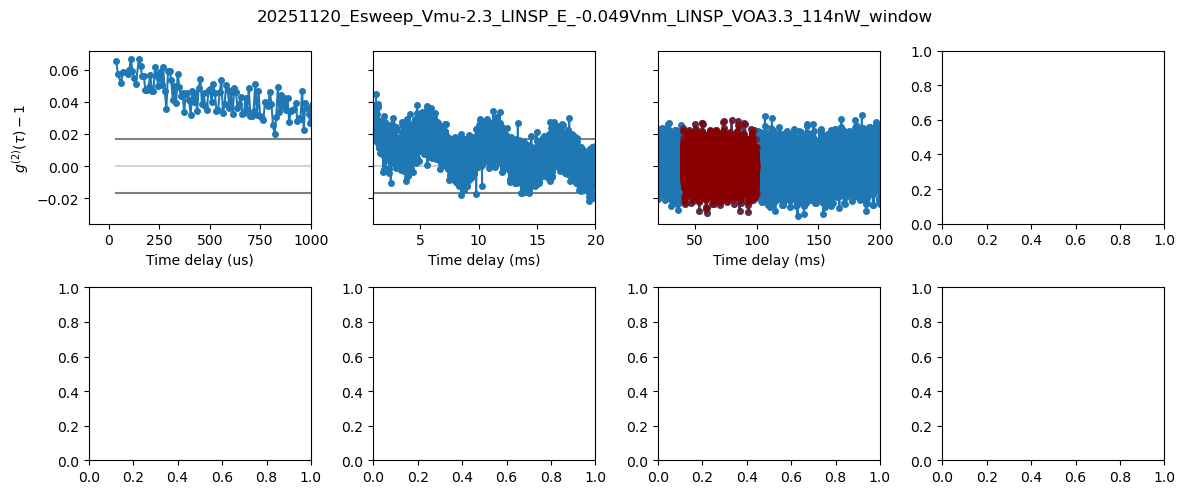

In [ ]:
## POWER SWEEP
# voas = np.array([2.9,3])#,3.1,3.3,3.35,3.4,3.45,3.5])
# names = [r"20251125_powersweep_Vmu-2.3_E-0.05_B-0.002_LINSP\VOA_"+f"{v}"+r"_LINSP\tests" for v in voas]

## MAGNETIC FIELD SWEEP
# Bs = np.arange(0.001,-0.01,-0.001)
# names = [r"20251124_Bsweep_Vmu-2.3_E-0.05_LINSP\B_"+f"{B:.3f}"+r"_-0.05Vnm_LINSP_VOA3.3_114nW_window\tests" for B in Bs]

# ## Electric FIELD SWEEP
# Es = np.concatenate((np.arange(0,-0.04,-0.005), np.arange(-0.040,-0.064,-0.001)))
Es = [-0.049]
names = [r"20251120_Esweep_Vmu-2.3_LINSP\E_"+f"{E:.3f}Vnm"+r"_LINSP_VOA3.3_114nW_window\tests" for E in Es]
chunks = np.zeros_like(Es,dtype=int)
# special = [(-0.046,2),(-0.047,2),(-0.048,1)]
# for e,c in special:
#     chunks[my_find_nearest(Es,e)]=int(c)


## Low power E field scan
# Es = [-0.036,-0.037,-0.039, -0.04,-0.042,-0.043,-0.046,-0.05,-0.053]
# names = [r"20251127_lowpower_80nW_Vmu-2.3_LINSP\E_"+f"{E:.3f}Vnm"+r"_LINSP_VOA3.45_80nW_window\tests" for E in Es]
# chunks = np.zeros_like(names,dtype = int)



## Low power at -3.1 at the PT
#Es = [-0.117]
#names = [r"20251203_Vmu-3.1_g2_PT_nu1_LINSP\Vmu_-3.1_E_"+f"{E:.3f}Vnm"+r"_LINSP_VOA3.65" for E in Es]
#chunks = np.zeros_like(names,dtype = int)

# higher power test to see whether oscillations are still there
Es = [-0.049]
names = [r"\20251204_Vmu-2.3_test_LINSP\Vmu_-2.3_E_"+f"{E:.3f}Vnm"+r"_LINSP_VOA3.1" for E in Es]
chunks = np.zeros_like(names,dtype = int)



for name, c in zip(names,chunks):
    home = r'Z:\Labs\G13\SSPDs\Olivier & Kilian MoTe2 Correlations'
    home = r'C:\Users\SSPDs\Documents\Offline SSPD Data'
    base = ntpath.join(home, name) 
    path = f"_chunk{c:d}.b"
    print(path,c)

    ch = 0
    g2mode = f"A{ch}"

    paths = (base, name, path)
    ### CALCULATE 
    filepath = ntpath.join(base, path)
    tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(filepath,
                                                chunk_ms=100_000,    
                                                tau_min_us= 0.2,     # tau max in microseconds
                                                tau_max_us= 200_000,     
                                                tau_bin_ps= 40e3,    # bin width in ps 
                                                n_workers= 7, 
                                                mode = g2mode,
                                                first_n_chunks = None,
                                                show_progress=True)

    print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
    print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 
    filepath_b = ntpath.join(base, path)

    tau_bin_ms = 5
    BASE_RES = 4e-12

    out_dir, files = analysis_cmd.correlate_b_file_classical(
        filepath= filepath_b,
        tau_bin_ms=tau_bin_ms,          
        chunk_minutes=1400/60,         
        block_records=10_000_000, 
        include_channels=ch, # none = all channels
        show_progress=True
    )


    #### PLOT
    analyze_all(paths,chunkname = f"_chunk{c:d}",g2mode = g2mode, ref_range_s=[0.8,1])

In [ ]:
analysis_setup()

Restricting to first 100 chunks.
Built 100 chunks in 2.8s.
Tasks100.0 % done, elapsed 31.5s  ETA 0.0ss
Correlation done in 31.9s; ch0=190273, ch1=286554
Correlation done.
[classical] File Z:\Labs\G13\SSPDs\Olivier & Kilian MoTe2 Correlations\20251120_Esweep_Vmu-2.3_LINSP\E_-0.049Vnm_LINSP_VOA3.3_114nW_window\tests\_chunk0.b (64688875 records)
[classical] dt=5 ms (dt_ticks=1250000000), chunk=23.333333333333332 min (chunk_ticks=350000000000000) -> 280000 bins/chunk including channels (none = all): 1.
 [classical autocorrelation] processed 100.0% (64688875/64688875) records
[classical] done in 6.4 s. Wrote 8 chunks to: Z:\Labs\G13\SSPDs\Olivier & Kilian MoTe2 Correlations\20251120_Esweep_Vmu-2.3_LINSP\E_-0.049Vnm_LINSP_VOA3.3_114nW_window\tests\_chunk0_classical_bins
[ANALYSIS - UTC 2025-12-04 14:41:02] Reading file with name _chunk0 in mode A1 from folder Z:\Labs\G13\SSPDs\Olivier & Kilian MoTe2 Correlations\20251120_Esweep_Vmu-2.3_LINSP\E_-0.049Vnm_LINSP_VOA3.3_114nW_window\tests


Tasks100.0 % done, elapsed 85.9s  ETA 0.0ss
Correlation done in 86.4s; ch0=1103861, ch1=1213169
Correlation done.
[classical] File Z:\Labs\G13\SSPDs\Olivier & Kilian MoTe2 Correlations\20251120_Esweep_Vmu-2.3_LINSP\E_-0.049Vnm_LINSP_VOA3.3_114nW_window\tests\_chunk0.b (64688875 records)
[classical] dt=5 ms (dt_ticks=1250000000), chunk=23.333333333333332 min (chunk_ticks=350000000000000) -> 280000 bins/chunk including channels (none = all): 1.
 [classical autocorrelation] processed 100.0% (64688875/64688875) records
[classical] done in 6.4 s. Wrote 8 chunks to: Z:\Labs\G13\SSPDs\Olivier & Kilian MoTe2 Correlations\20251120_Esweep_Vmu-2.3_LINSP\E_-0.049Vnm_LINSP_VOA3.3_114nW_window\tests\_chunk0_classical_bins
[ANALYSIS - UTC 2025-12-04 14:35:05] Reading file with name _chunk0 in mode A1 from folder Z:\Labs\G13\SSPDs\Olivier & Kilian MoTe2 Correlations\20251120_Esweep_Vmu-2.3_LINSP\E_-0.049Vnm_LINSP_VOA3.3_114nW_window\tests
Analysis server reached.
File Z:\Labs\G13\SSPDs\Olivier & Kilia

Rebinning from 12499995 to 62499
Bin size  8000.0  ns
Reference range [0.04, 0.1] s used to correct linear background and show statistics


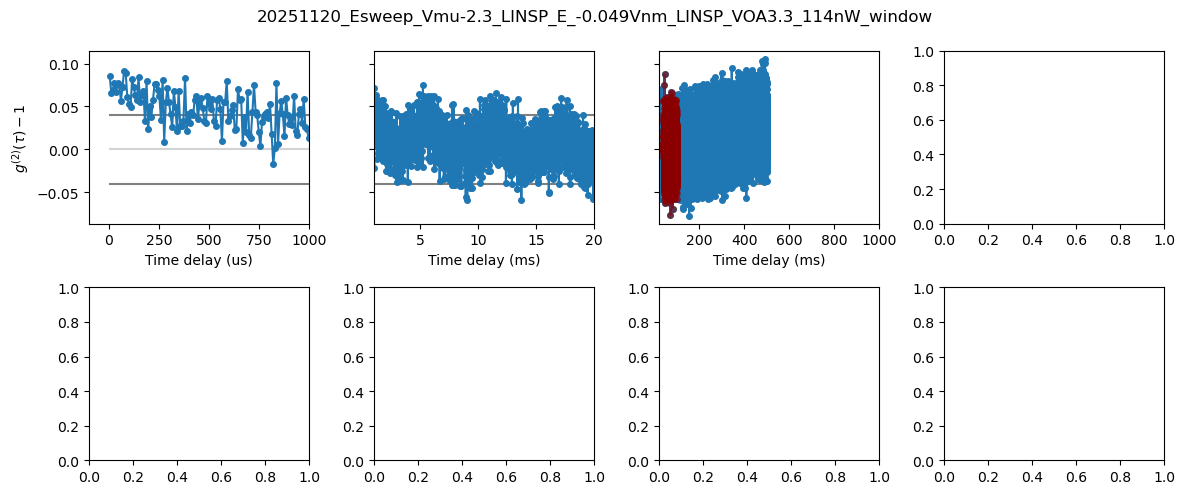

In [54]:
analyze_all(paths,chunkname = f"_chunk{c:d}",g2mode = g2mode, ref_range_s=[0.8,1])

Rebinning from 2499995 to 12499
Bin size  8000.0  ns
Reference range [0.04, 0.1] s used to correct linear background and show statistics
C:\Users\SSPDs\Documents\Offline SSPD Data\20251203_Vmu-3.1_g2_PT_nu1_LINSP\Vmu_-3.1_E_-0.115Vnm_LINSP_VOA3.65\_chunk0_classical_bins
Indices of chunks loaded:  [0 0 1 1]
Chunk durations (min): [53, 53, 53, 53]
Absolute time (s):  [   0.    0. 3200. 3200.]
Bin size (ms):  [5. 5. 5. 5.]
Bins in each chunk (million):  0.64
New bins in each chunk (million):  0.128
Bin size: 0.025  s


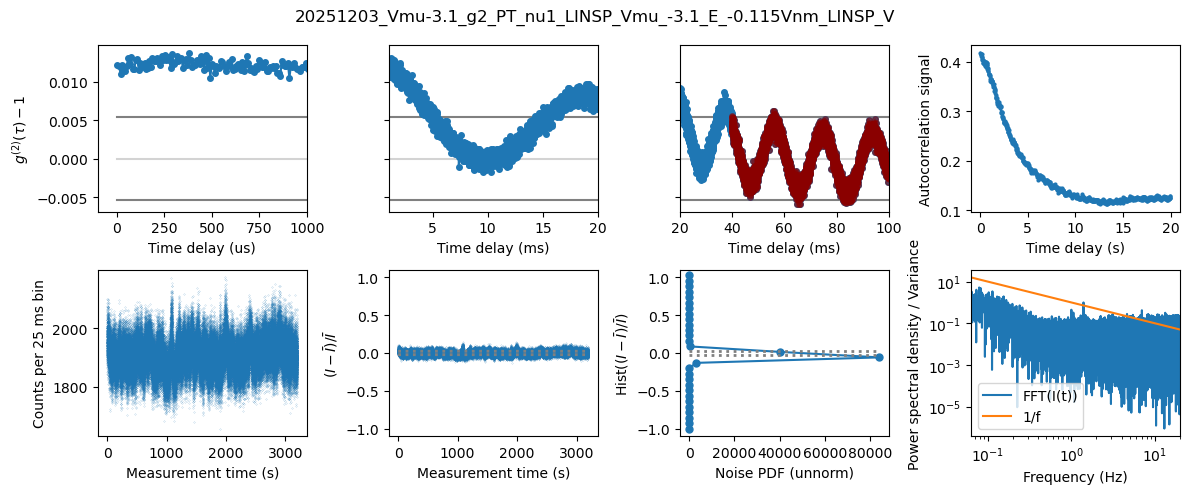

In [11]:
analyze_all(paths,chunkname = f"_chunk{c:d}",g2mode = "A0")